### Código para plotar glitchramas
Começamos com a importação das bibliotecas necessárias

In [95]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import pickle
import os

Este é a função que faz o plot dos glitchgramas, tendo 3 variáveis, o trigger central que define o glitch:

- `list_of_gpstimes`: é o trigger central do glitch
- `interval`: a janela de tempo do glitch
- `label`: para esse caso, os glitches clusterizados tem uma etiqueta com o nome da sua classe

Aqui consideraria também o valor de `q`, mas no arquivo que estava usando para não ficar muito grande, excluí essa coluna.

O grande lance é fazer uma imagem "pixelada" do glitch numa matriz 41x30, usando o trigger mais intenso, ou seja, com o razão sinal ruído (SNR) mais alto dentro desse espaço

In [100]:
unclustered = pd.read_pickle('clustered_triggers.pkl')
clustered_omicron = pd.read_csv('O4b_predictions_v1.0_pre_gw_exclusion.csv')        #Os dados daqui são para 1 mês, ou seja, do mês de abril de 2024
clustered_omicron = clustered_omicron[clustered_omicron['GPStime'] < 1399300195]    #O arquivo tem os dados da O4b inteira, então tive que limitar para que coincida com o clustered_omicron

def plotting_glitchgrams(list_of_gpstimes, interval, label):
    """
    list_of_gpstimes: é o trigger central do glitch
    interval: a janela de tempo do glitch
    label: para esse caso, os glitches clusterizados tem uma etiqueta com o nome da sua classe
    """
    nt=41       #divisão horizontal/temporal de bins(quadradinhos)
    nf=30       #divisão vertical/frequência de bins(quadradinhos)
    deltat = interval

    #parâmetros da transformada q

    #q1 = 1         #Opcional caso tenha a coluna com as transformadas q
    #q2 = 150       #Opcional caso tenha a coluna com as transformadas q

    #Criação dos bins
    
    tbins=np.linspace(-deltat,deltat,nt)                #Bin de -deltat até +deltat, divididos em espaços iguais a nt
    fbins=np.logspace(np.log10(3),np.log10(8192),nf)    #A mesma coisa, mas para a frequência

    #Selecionando os triggers dentro da janela

    for gpstime in list_of_gpstimes:
        selected= np.logical_and(t0>(gpstime-deltat),t0<(gpstime+deltat))# we want parameters in an interval of detalt and Q<80
        #selected2= np.logical_and(q>=q1, q<=q2)
        #selected= np.logical_and(selected1)
        snrs=snr[selected]
        t0s=t0[selected]-gpstime #t0s é o trigger central da janela temporal
        fcs=fc[selected]


        df = pd.DataFrame({'t0s':t0s, 'fcs':fcs, 'snrs':snrs})
        color=[("red" if s>20 else "green" if s>10 else "xkcd:light blue") for s in (snrs)]
        df['color'] = color
        df = df.sort_values(by='snrs')

        #parâmetros do plot

        plt.figure(figsize=(10,8))
        plt.set_cmap('jet')
        plt.scatter(df['t0s'],df['fcs'],c=df['color'],marker='.', s=65)
        plt.ylim(3,8192)
        plt.gca().set_yscale('log')
        plt.gca().set_xlabel('Time [s]',fontsize = 28)
        plt.gca().set_ylabel('Frequency [Hz]',fontsize = 28)
        plt.gca().set_xlim([-deltat,deltat])
        plt.title(str(gpstime) + ' - ' + label)
        plt.xticks(np.arange(-0.5,1,0.5),size=24)
        plt.yticks(size=24)
        plt.ylim(10,4096)
        legend_elements = [Line2D([0], [0], marker='o', color='w', label=r'SNR>20',markerfacecolor='r', markersize=15),
                            Line2D([0], [0], marker='o', color='w', label=r'$10 \leq SNR\leq20$',markerfacecolor='g', markersize=15),
                            Line2D([0], [0], marker='o', color='w', label=r'SNR<10',markerfacecolor='xkcd:light blue', markersize=15)]

        # Criação do plot
        plt.legend(handles=legend_elements, fontsize='20')
        #plt.title(f'Q-value = {qvalue}', fontsize = '32')
        tempo_str = f"{gpstime:.2f}".replace('.', '_')

        #definição de salvamento da imagem

        nome_arq = f"Glitch_{tempo_str}_{label}_{interval}.png"
        path = r'C:\Users\leyzi\Documents\ITA\Virgo\Detchar\UMAP\UMAP\O4b\Imagens classes'
        caminho_completo = os.path.join(path, nome_arq)
        plt.tight_layout()
        plt.savefig(caminho_completo, dpi=150, bbox_inches='tight')
        
        plt.show()
        return df


Aqui analizamos a quantidade de triggers por snr

In [101]:
np.logspace(np.log10(10),np.log10(2048),50)

array([  10.        ,   11.14730795,   12.42624746,   13.85192071,
         15.4411626 ,   17.21273946,   19.18757075,   21.388976  ,
         23.84295023,   26.57847087,   29.62783997,   33.02706562,
         36.81628712,   41.04024903,   45.74882944,   50.99762902,
         56.84862756,   63.37091582,   70.64151139,   78.74626817,
         87.78089015,   97.85206149,  109.07870633,  121.59339306,
        135.54389975,  151.09495918,  168.43020401,  187.75433528,
        209.29553949,  233.30818319,  260.07581661,  289.91452189,
        323.17664557,  360.25495915,  401.58729713,  447.66172713,
        499.02231312,  556.27553999,  620.09747512,  691.24175162,
        770.54846755,  858.95410607,  957.50259381, 1067.35762793,
       1189.81641748, 1326.32500136, 1478.49532363, 1648.124268  ,
       1837.21487608, 2048.        ])

Text(0.5, 1.0, 'Counts per snr for april 2024')

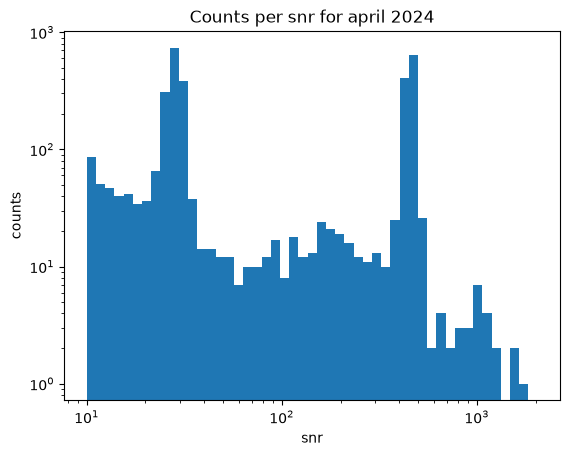

In [102]:
plt.figure()
plt.hist(clustered_omicron['snr'], bins= np.logspace(np.log10(10),np.log10(2048),50))
plt.yscale('log')
plt.xscale('log')
plt.xlabel('snr')
plt.ylabel('counts')
plt.title('Counts per snr for april 2024')

Separando e contando as classes de glitches

In [66]:
ExL = clustered_omicron[clustered_omicron['label'] == 'Extremely_Loud']
K_f = clustered_omicron[clustered_omicron['label'] == 'Koi_Fish']
blip = clustered_omicron[clustered_omicron['label'] == 'Blip']
n_glitch = clustered_omicron[clustered_omicron['label'] == 'No_Glitch']
scat = clustered_omicron[clustered_omicron['label'] == 'Scattering']
tomte = clustered_omicron[clustered_omicron['label'] == 'Tomte']

print('Extremely Loud:', len(ExL))
print('Koi Fish:', len(K_f))
print('Blip:', len(blip))
print('No Glitch:', len(n_glitch))
print('Scattering:', len(scat))
print('Tomte:', len(tomte))


Extremely Loud: 1302
Koi Fish: 387
Blip: 116
No Glitch: 146
Scattering: 347
Tomte: 1385


Só um arranjo para limpar os dados clusterizados, tendo apenas duas colunas, o `GPStime` e o `label`

In [ ]:
glitches = [ExL, K_f, blip, n_glitch, scat, tomte]

glitch_names = []

for glitch in glitches:
    gpstimes = glitch['GPStime'].values 
    label = glitch['label'].values      
    
    array_temp = np.column_stack((gpstimes, label))     #coloca os valores de gpstime e label na mesma linha em um arquivo novo
    
    glitch_names.append(array_temp)                     #salva na próxima linha

# Agora juntamos todos os arrays em um único array 2D
array_final = np.concatenate(glitch_names, axis=0)

print(array_final.shape)
print(array_final[-10:])
print(array_final[10:])  

(3683, 2)
[[1398782154.554687 'Tomte']
 [1398832884.177734 'Tomte']
 [1398885953.230468 'Tomte']
 [1398892487.886718 'Tomte']
 [1398912128.919922 'Tomte']
 [1399041453.621093 'Tomte']
 [1399160972.035156 'Tomte']
 [1399176430.214843 'Tomte']
 [1399176453.839843 'Tomte']
 [1399255850.964843 'Tomte']]
[[1396892253.43164 'Extremely_Loud']
 [1396892743.042968 'Extremely_Loud']
 [1396893220.197265 'Extremely_Loud']
 ...
 [1399176430.214843 'Tomte']
 [1399176453.839843 'Tomte']
 [1399255850.964843 'Tomte']]


***
Foi feito uma separação de 20 glitches de cada classe com tempos aleatórios

In [ ]:
import random


classes_unicas = np.unique(array_final[:, 1])
print(f"Classes encontradas: {classes_unicas}")

# Lista para guardar os arrays de 20 itens de cada classe
amostras_20 = []

for classe in classes_unicas:
    # 1. Filtra apenas as linhas da classe atual
    linhas_classe = array_final[array_final[:, 1] == classe]
    
    # 2. Verifica se tem pelo menos 20 itens para não dar erro
    if len(linhas_classe) >= 20:
        # Sorteia 20 índices aleatórios
        indices_sorteados = random.sample(range(len(linhas_classe)), 20)
        amostra = linhas_classe[indices_sorteados]
    else:
        # Se tiver menos de 20, pega todos
        amostra = linhas_classe
        
    amostras_20.append(amostra)
    print(f"{classe}: {len(amostra)} amostras sorteadas.")

# 3. Junta todos os 20 itens de cada classe em um único array
array_balanceado = np.concatenate(amostras_20, axis=0)

print(f"\nShape final do array balanceado: {array_balanceado.shape}")

Classes encontradas: ['Blip' 'Extremely_Loud' 'Koi_Fish' 'No_Glitch' 'Scattering' 'Tomte']
Blip: 20 amostras sorteadas.
Extremely_Loud: 20 amostras sorteadas.
Koi_Fish: 20 amostras sorteadas.
No_Glitch: 20 amostras sorteadas.
Scattering: 20 amostras sorteadas.
Tomte: 20 amostras sorteadas.

Shape final do array balanceado: (120, 2)


In [78]:
t0 = np.array(list(unclustered['time']))
fc = np.array(list(unclustered['frequency']))
snr = np.array(list(unclustered['snr']))

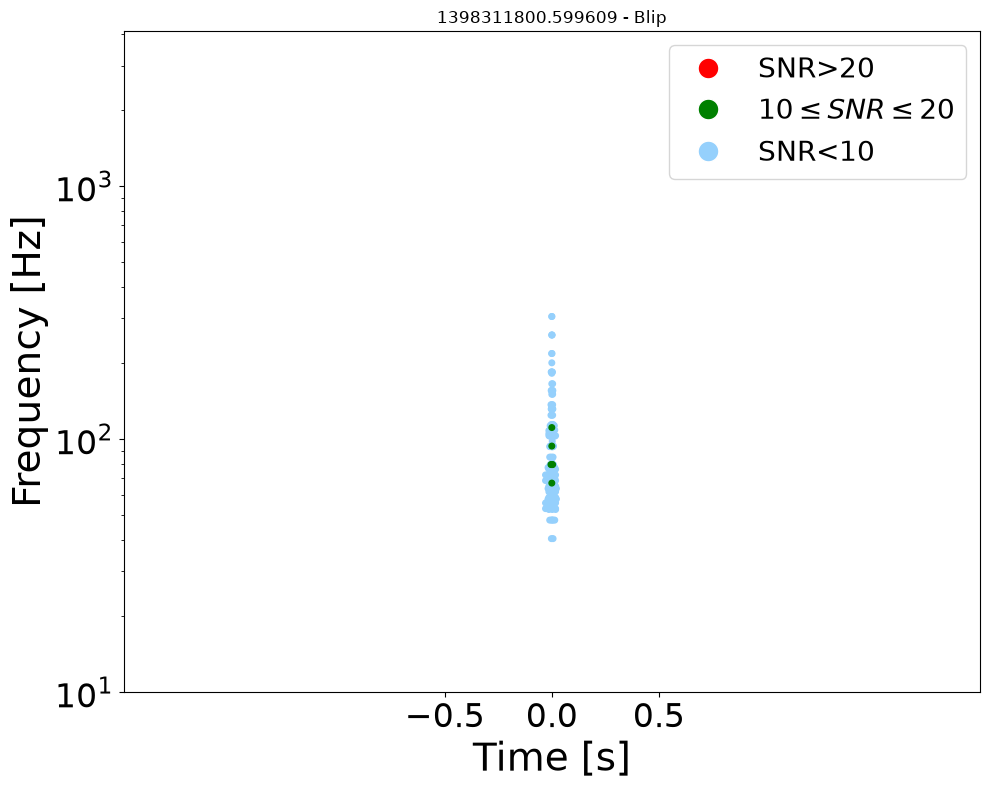

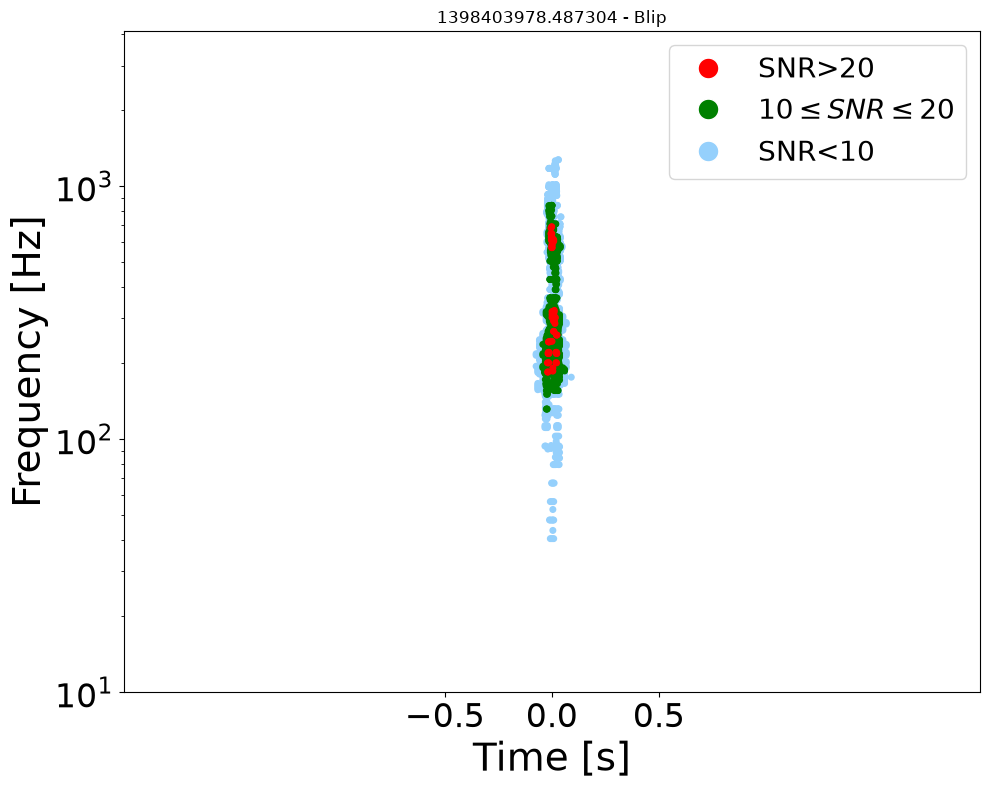

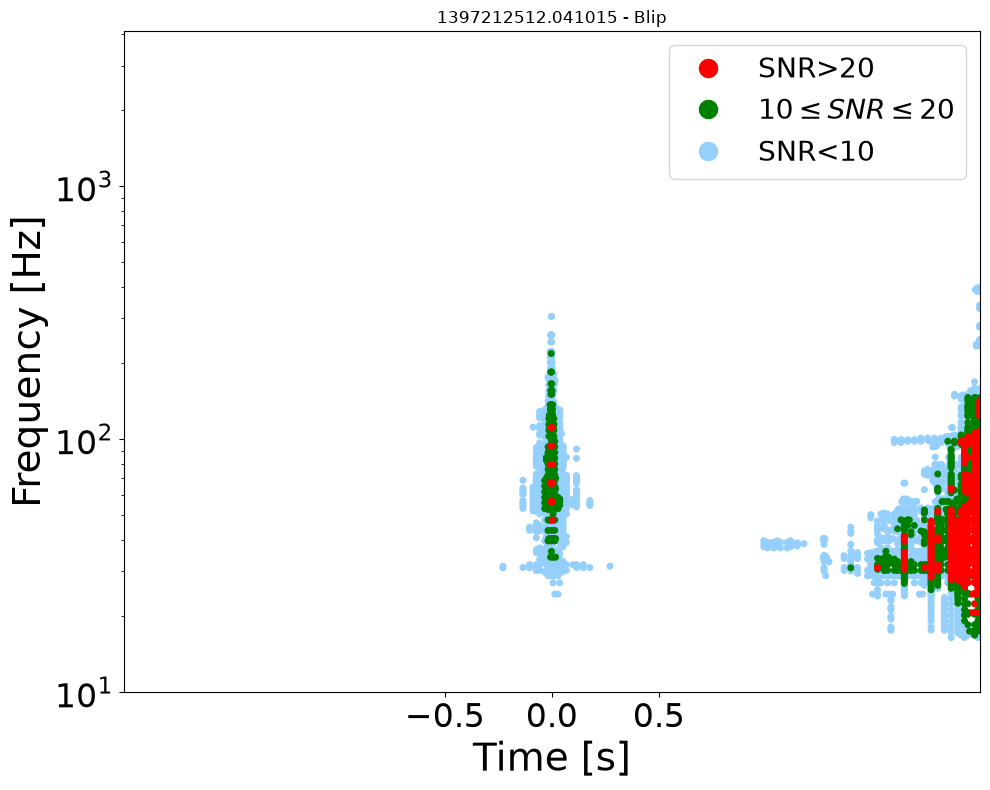

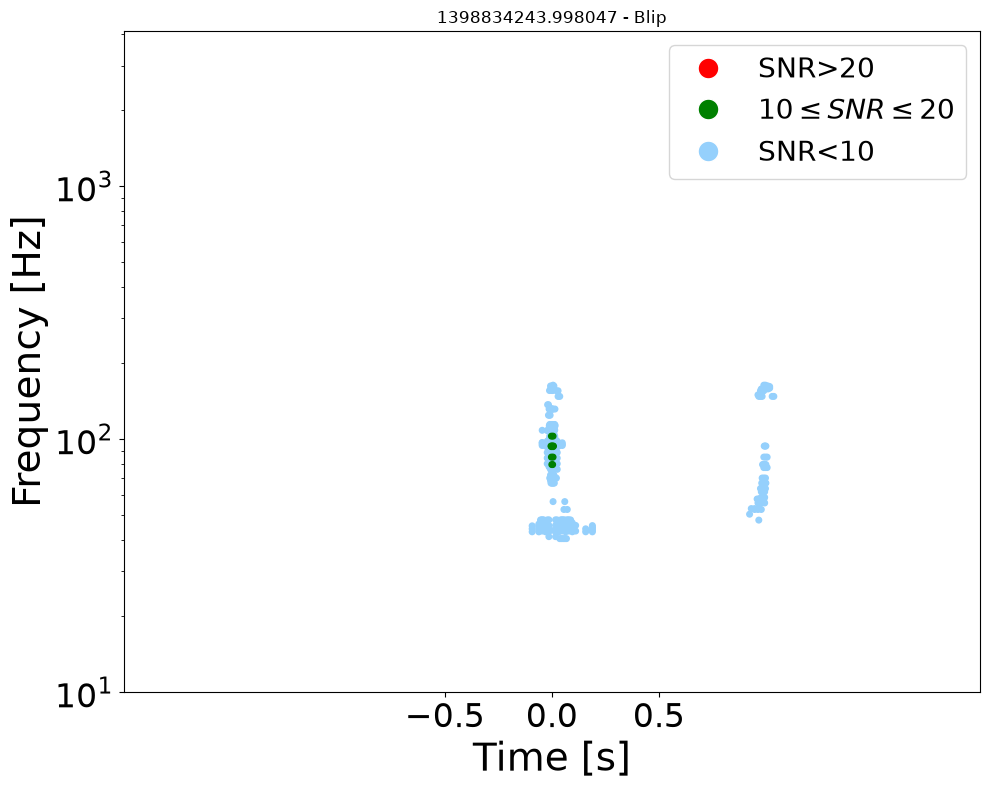

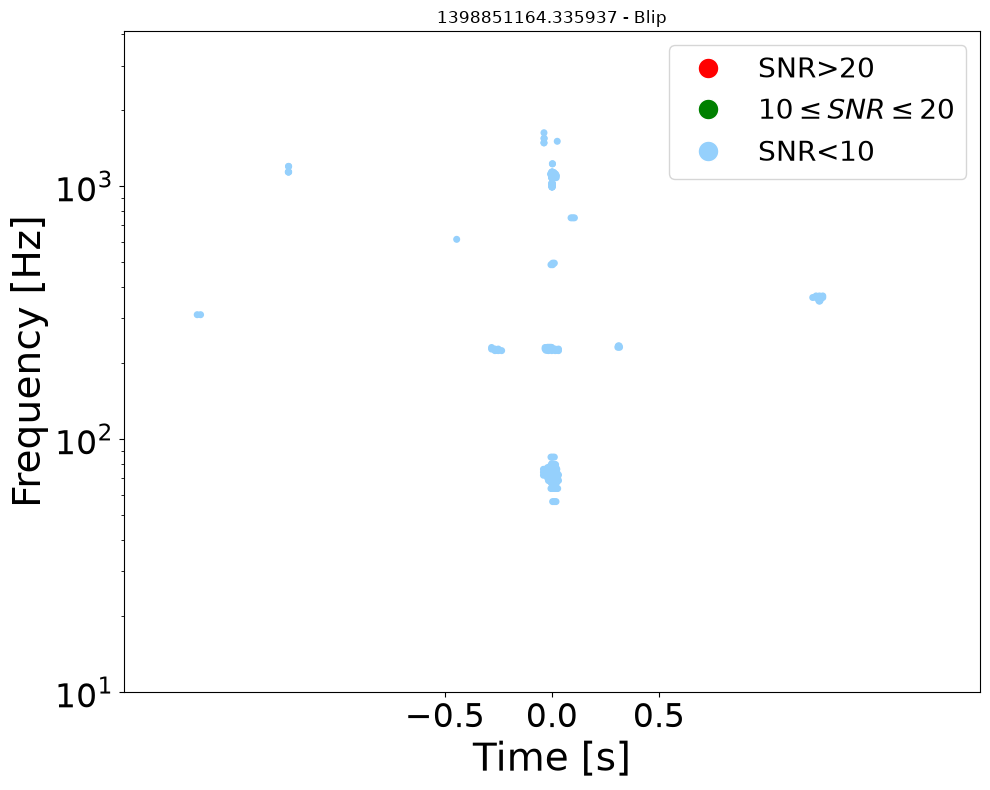

...

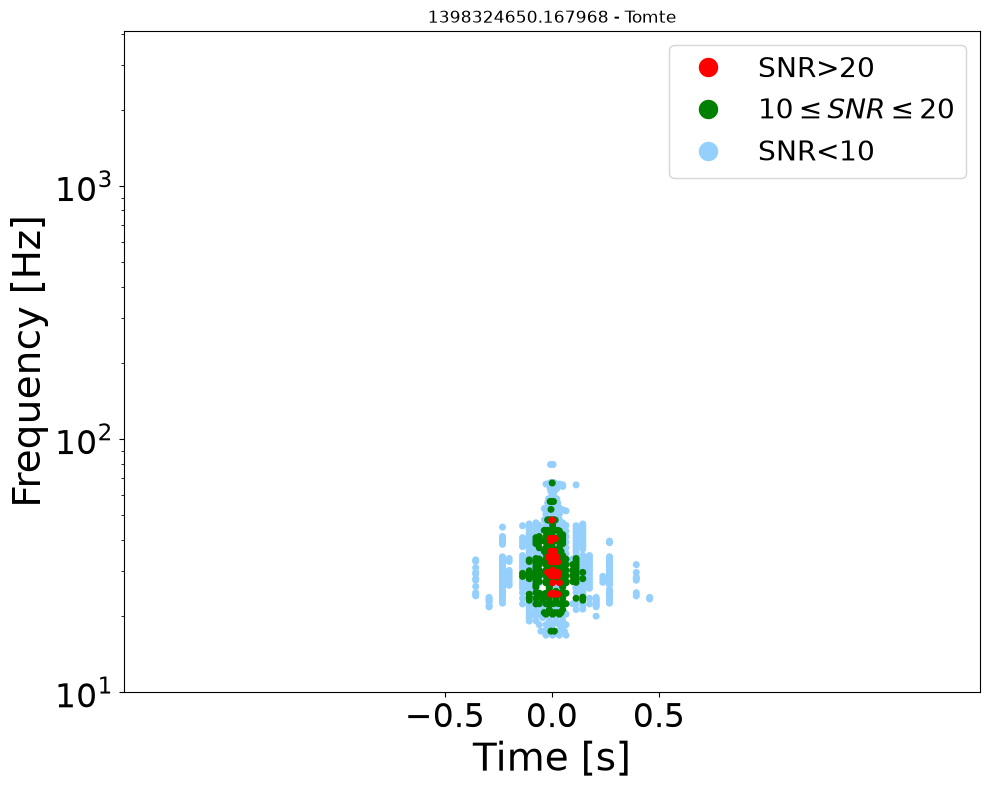

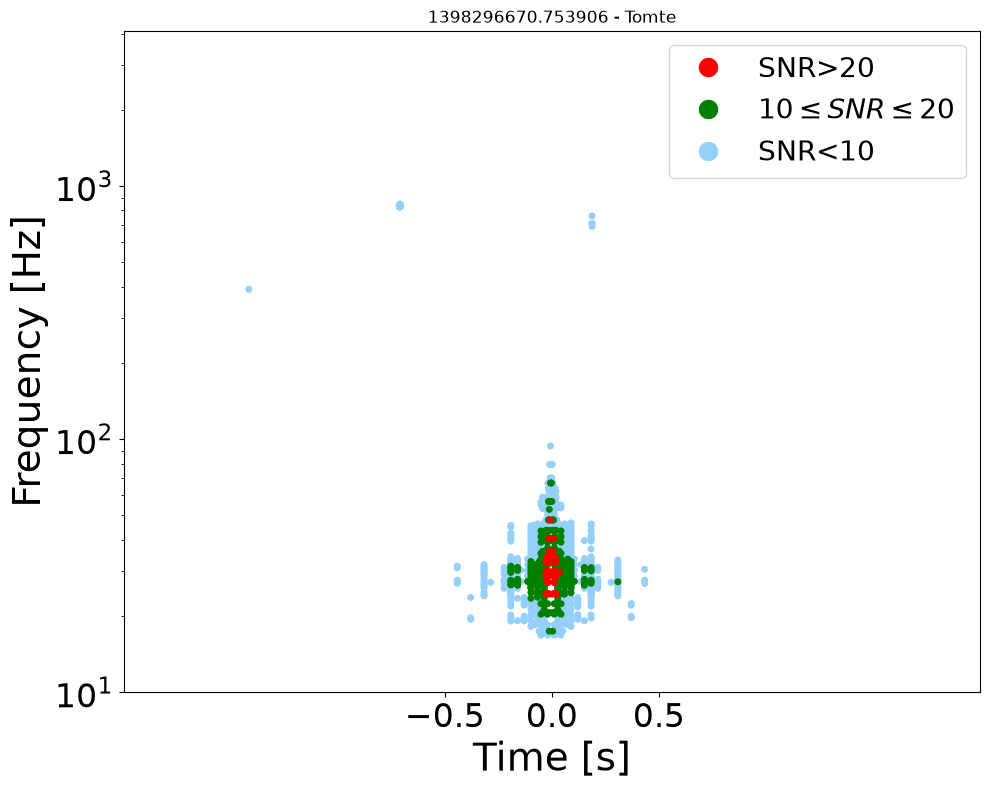

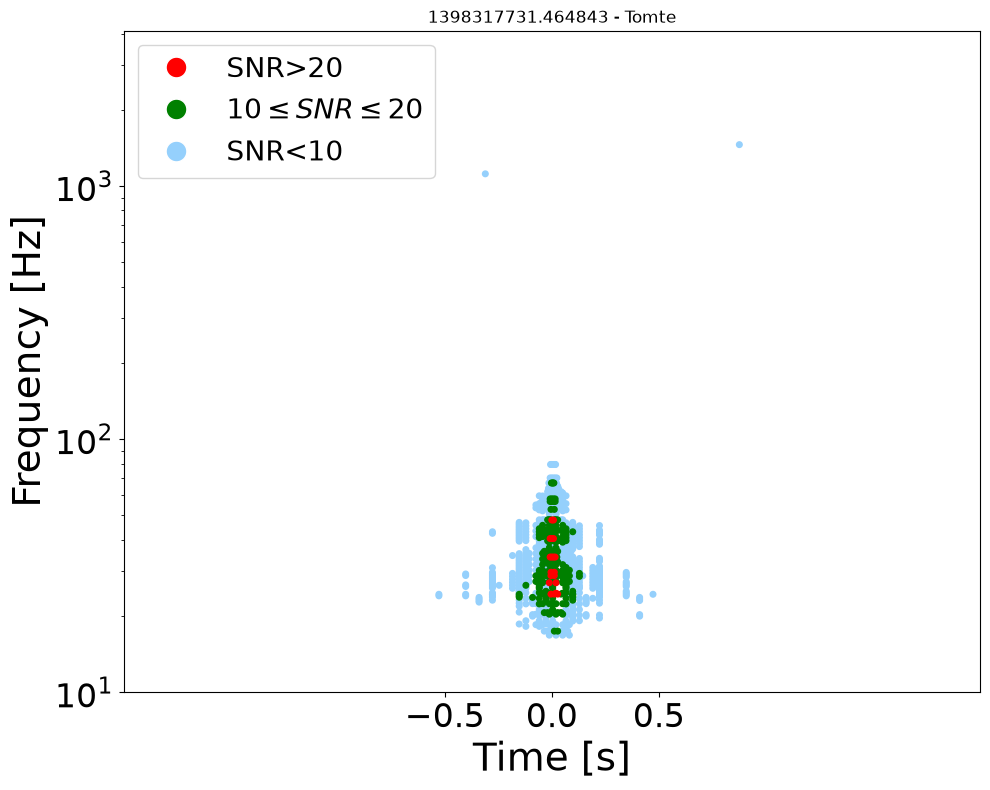

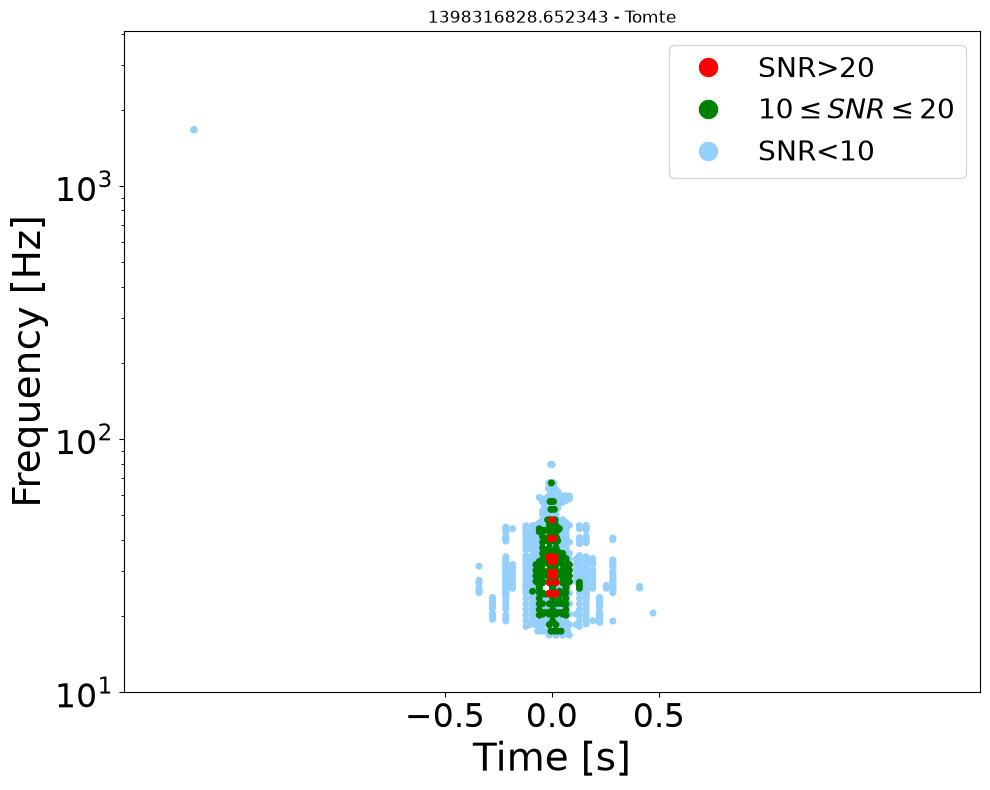

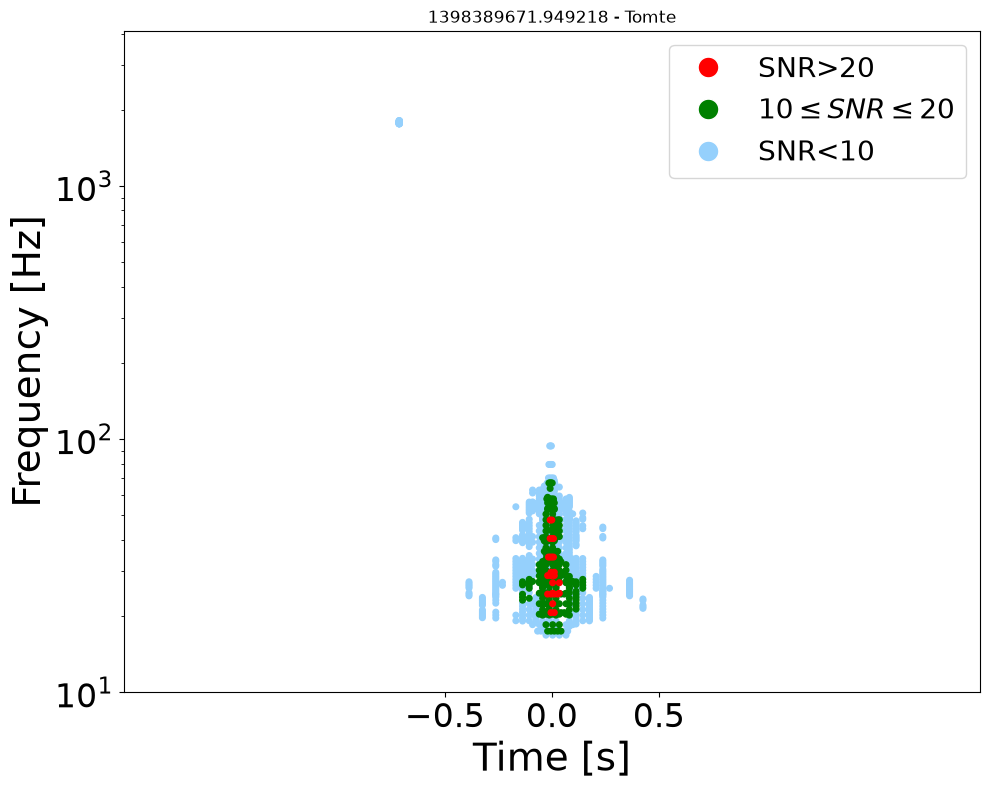

In [ ]:
gps = array_balanceado[:, 0]    #indicando a primeira coluna do array

lab = array_balanceado[:, 1]    #indicando a segunda coluna do array

for i, j in zip(gps, lab):   
    plotting_glitchgrams([i], interval = 2, label=j)